# 📘 Data Science for Retail Decision Support Using ML and Generative AI

In [1]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import textwrap
import os
import chromadb

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.metrics import r2_score, get_scorer_names, silhouette_score
from sklearn.model_selection import cross_validate
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans

from dotenv import load_dotenv
from openai import OpenAI
from chromadb.utils import embedding_functions
from typing import List, Dict


In [2]:
# Load the Dataset
df = pd.read_csv(r'finalproject_black-friday\BlackFriday.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 537577 entries, 0 to 537576
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     537577 non-null  int64  
 1   Product_ID                  537577 non-null  str    
 2   Gender                      537577 non-null  str    
 3   Age                         537577 non-null  str    
 4   Occupation                  537577 non-null  int64  
 5   City_Category               537577 non-null  str    
 6   Stay_In_Current_City_Years  537577 non-null  str    
 7   Marital_Status              537577 non-null  int64  
 8   Product_Category_1          537577 non-null  int64  
 9   Product_Category_2          370591 non-null  float64
 10  Product_Category_3          164278 non-null  float64
 11  Purchase                    537577 non-null  int64  
dtypes: float64(2), int64(5), str(5)
memory usage: 49.2 MB


In [3]:
# How many fields are missing.
print(f'Total number of records: {df.shape[0]}')
num_features = df.select_dtypes(include='number')
cat_features = df.select_dtypes(exclude='number')
print(f'Number of missing values in numeric features:\n{num_features.isnull().sum()}\n')
print(f'Number of missing values in categorical features:\n{cat_features.isnull().sum()}')

Total number of records: 537577
Number of missing values in numeric features:
User_ID                    0
Occupation                 0
Marital_Status             0
Product_Category_1         0
Product_Category_2    166986
Product_Category_3    373299
Purchase                   0
dtype: int64

Number of missing values in categorical features:
Product_ID                    0
Gender                        0
Age                           0
City_Category                 0
Stay_In_Current_City_Years    0
dtype: int64


In [4]:
# Show the cardinality of the categorical variables
df[cat_features.columns].nunique()

Product_ID                    3623
Gender                           2
Age                              7
City_Category                    3
Stay_In_Current_City_Years       5
dtype: int64

The very high cardinality of the Product_ID feature is probably too difficult to feature engineer, so it will be dropped. 

In [5]:
# Display the possible valuesx of the remaining categorical fields.
print('Gender values:', df['Gender'].unique(), '\n')
print('Age values:', df['Age'].unique(), '\n')
print('City Category values:',df['City_Category'].unique(), '\n')
print('Stay in Current City Years values:', df['Stay_In_Current_City_Years'].unique(), '\n')

Gender values: <StringArray>
['F', 'M']
Length: 2, dtype: str 

Age values: <StringArray>
['0-17', '55+', '26-35', '46-50', '51-55', '36-45', '18-25']
Length: 7, dtype: str 

City Category values: <StringArray>
['A', 'C', 'B']
Length: 3, dtype: str 

Stay in Current City Years values: <StringArray>
['2', '4+', '3', '1', '0']
Length: 5, dtype: str 



Gender only has 2 values, making it suitable for binary encoding. Age and Stay_In_Current_City_Years appear to have a natural order, making them suitable for Ordinal encoding. City Category is suitable for One-Hot encoding.

In [6]:
# Binary encode the Gender feature
df['Gender'] = (df['Gender'] == 'F').astype(int)
print('Gender values:', df['Gender'].unique(), '\n')
# Perform ordinal encoding on Stay in Current City Years by removing the + from 4+ and converting to integer
df['Stay_In_Current_City_Years'] = df['Stay_In_Current_City_Years'].map(lambda x: x.replace('+', '')).astype(int)
print('Stay in Current City Years values:', df['Stay_In_Current_City_Years'].unique(), '\n')

Gender values: [1 0] 

Stay in Current City Years values: [2 4 3 1 0] 



## 📊 Visualize the Dataset

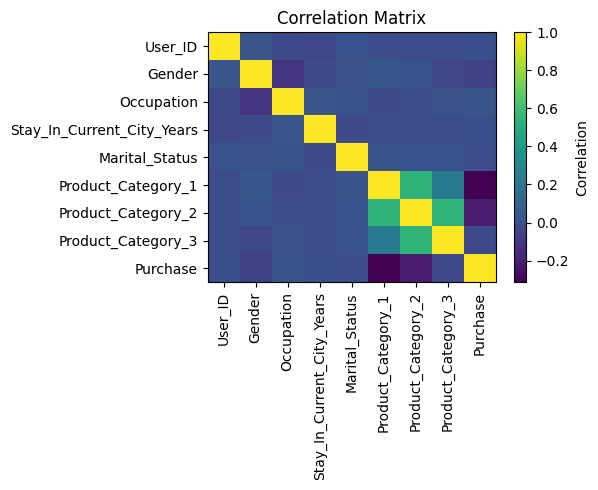

In [7]:
# Generate a correlation matrix for the numeric features
num_features = df.select_dtypes(include='number')
cat_features = df.select_dtypes(exclude='number')
corr = num_features.corr()

plt.figure(figsize=(6,5))
plt.imshow(corr, aspect="auto")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.colorbar(label="Correlation")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [8]:
# Rank correlations
corr['Purchase'].sort_values(ascending=False)

Purchase                      1.000000
Occupation                    0.021104
Stay_In_Current_City_Years    0.005470
User_ID                       0.005389
Marital_Status                0.000129
Product_Category_3           -0.022257
Gender                       -0.060086
Product_Category_2           -0.209973
Product_Category_1           -0.314125
Name: Purchase, dtype: float64

There does not appear to be a strong correlation between most of the numeric fields and Purchase. The exceptions are Product_Category_1 and Product_Category_2, which show a modest negative correlation.   

City_Category
A    8958.011014
B    9198.657848
C    9844.441855
Name: Purchase, dtype: float64


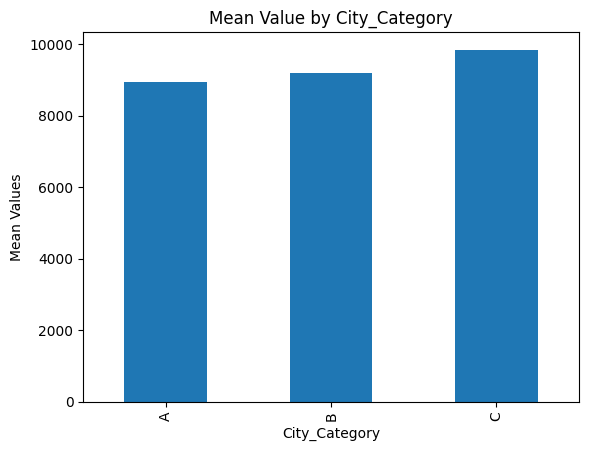

In [9]:
means = df.groupby('City_Category')['Purchase'].mean()
print(means)
means.plot(kind='bar')
plt.ylabel('Mean Values')
plt.title('Mean Value by City_Category')
plt.show()

It appears that City_Category might have some impact on Purchase.

Age
0-17     9020.126878
18-25    9235.197575
26-35    9314.588970
36-45    9401.478758
46-50    9284.872277
51-55    9620.616620
55+      9453.898579
Name: Purchase, dtype: float64


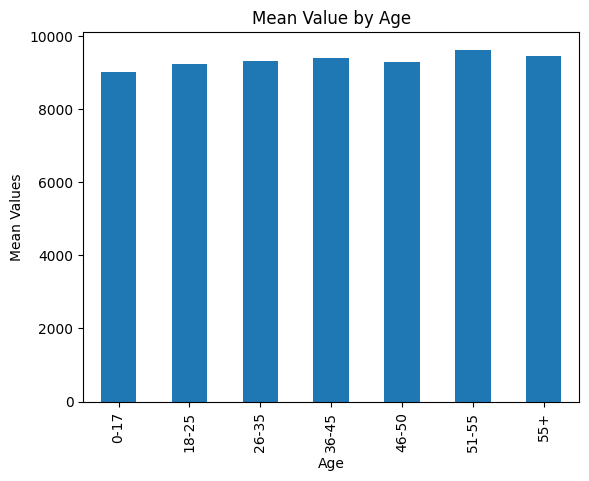

In [10]:
means = df.groupby('Age')['Purchase'].mean()
print(means)

means.plot(kind='bar')
plt.ylabel('Mean Values')
plt.title('Mean Value by Age')
plt.show()

Age does not appear to be a significant impact on Purchase.

## 🧹 Data Preparation

In [11]:
# Drop Product_ID
df = df.drop('Product_ID', axis=1)
# Remove exact duplicate rows
df = df.drop_duplicates()
# Data transformations:
num_features = df.select_dtypes(include='number')
cat_features = df.select_dtypes(exclude='number')
# Fill remaining missing values with median for numeric columns.
num_pipe = Pipeline([
    ('numericalImputer', SimpleImputer(strategy='median')),
    ('numericalScaler', StandardScaler())
])
# No need for an imputer for the categorical features, since neither has any missing values.
age_pipe = Pipeline([
    ('ageEncoder', OrdinalEncoder(categories=[['0-17', '18-25', '26-35', '36-45', '46-50', '51-55', '55+']]))
])
city_cat_pipe = Pipeline([
    ('cityEncoder', OneHotEncoder())
])
# Make column transformer
col_transformer = ColumnTransformer(transformers=[
    ('numerical', num_pipe, num_features.columns.drop('Purchase')),
    ('age', age_pipe, ['Age']),
    ('city_cat', city_cat_pipe, ['City_Category'])])

X = df.drop(columns=['Purchase'])
y = df['Purchase']

## ✂️ Train-Test Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 🤖 Train the Model

In [13]:
def trainer(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    # Evaluation
    print("    R2:", r2_score(y_test, y_pred))    
    # Cross validation
    scores = cross_validate(model, X_train, y_train, cv=5, scoring=('r2'))
    print('  Cross-validation:')
    print('    R2 score:', scores['test_score'].mean())
    print('\n')

## 🔮 Run Pipelines

In [14]:
#print(get_scorer_names())
lg_model = Pipeline([
    ('columnTransformer', col_transformer),
    ('estimator', LinearRegression())
])
trainer(lg_model, X_train, y_train, X_test, y_test)

    R2: 0.10547546445982647
  Cross-validation:
    R2 score: 0.10935180912201095




The Linear Regression model doesn't seem to provide much insights. Let's use clustering to find hidden patterns.

## 🔮 Use KMeans Clustering to Find Hidden Patterns

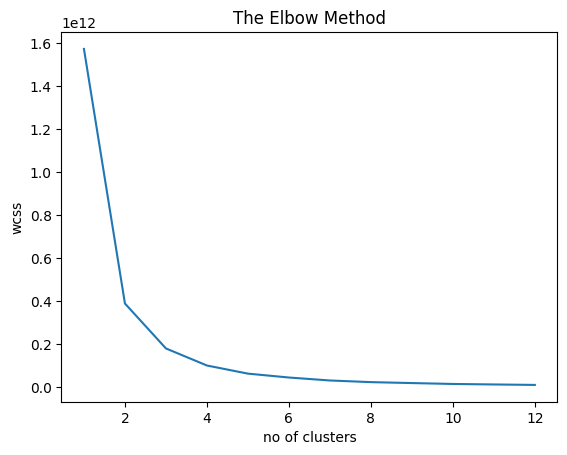

In [15]:
df = df.fillna({'Product_Category_2': df['Product_Category_2'].mean(), 'Product_Category_3': df['Product_Category_3'].mean()})
df['Age'] = df['Age'].replace({'0-17': 0, '18-25': 1, '26-35': 2, '36-45': 3, '46-50': 4, '51-55': 5, '55+': 6}).astype(int)
df = pd.get_dummies(df, 'City_Category', drop_first=True)

rng = range(1,df.shape[1] + 1)
# decide the optimum cluster number using Elbow Mmethod to figure out K for KMeans
#wcss - within-cluster sum of squares 
wcss=[]
drop_df = df.drop('Purchase',axis=1)
for i in rng:
    kmeans = KMeans(n_clusters= i, random_state=23)
    kmeans.fit(drop_df)
    wcss.append(kmeans.inertia_)

#Visualizing the ELBOW method to get the optimal value of K 
plt.plot(rng, wcss)
plt.title('The Elbow Method')
plt.xlabel('no of clusters')
plt.ylabel('wcss')
plt.show()


The last elbow is at 4.

Silhouette Score:  0.5305451407362252
Cluster
0     7470.712232
1    17380.573367
2     3725.253136
3    11279.893005
Name: Purchase, dtype: float64


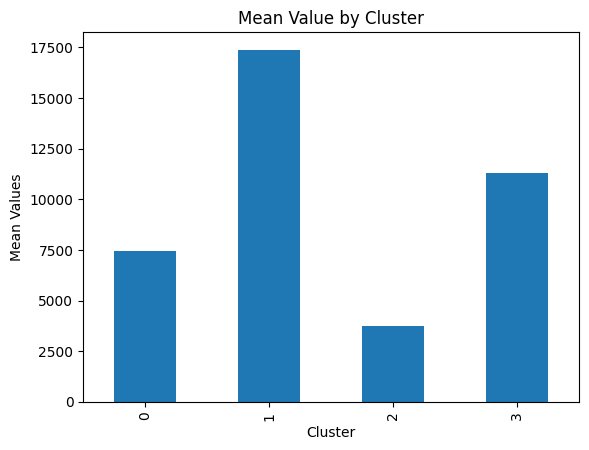

In [16]:
kmeansmodel = KMeans(n_clusters=4, random_state=23)
kmeansmodel.fit(df)
df['Cluster'] = kmeansmodel.predict(df)

# Calculate silhouette score on sample of 100,000 since the calculation was taking too long on the entire dataframe.
print('Silhouette Score: ',silhouette_score(df.drop(['Purchase', 'Cluster'],axis=1), kmeans.labels_, sample_size=100000, random_state=42))

means = df.groupby('Cluster')['Purchase'].mean()
print(means)

means.plot(kind='bar')
plt.ylabel('Mean Values')
plt.title('Mean Value by Cluster')
plt.show()

The silhoutte score of positive 0.53 indicates that these are good clustering results. 

In [17]:
load_dotenv()
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
print("OPENAI_API_KEY set:", bool(OPENAI_API_KEY))
client = OpenAI(api_key=OPENAI_API_KEY)
chroma_client = chromadb.Client()
openai_ef = embedding_functions.OpenAIEmbeddingFunction(
    api_key=OPENAI_API_KEY,
    model_name="text-embedding-3-small"
)
test_response = client.responses.create(
    model='gpt-5-mini',
    input='What is 5 divided by 2'
)
print(test_response.output_text)

OPENAI_API_KEY set: True
5 ÷ 2 = 2.5. 

As a fraction it's 5/2, or as a mixed number 2 1/2 (2 with remainder 1).


In [18]:
knowledge_base = [ 
    {
        'id': '01_average_purchase_by_city_category',
        'title': 'Average Purchase by City Category',
        'text': (
            'Of the 3 city categories, category C has the highest average purchase amount of $9844,'
            'followed by category B with an average purchase amount of $9198,'
            'and category A with an averge purchase amount of $8958.'
        )
    },
    {
        'id': '02_average_purchase_by_cluster',
        'title': 'Average Purchase by Cluster',
        'text': (
            'Of the 4 clusters, cluster 1 has the highest average purchase amount of $17380,'
            'followed by cluster 3 with an average purchase amount of $11279,'
            'category 0 with an averge purchase amount of $7470,'
            'and category 2 with an averge purchase amount of $3725'
        )
    },
    {
        'id': '03_correlation_between_product_category_and_purchase',
        'title': 'Correlation Between Product Category and Purchase',
        'text': (
            'Of the 3 product categories, product category 1 has a modest negative correlation with purchase,'
            'product category 2 also has a modest negative correlation with purchase,'
            'though its correlation is not as strong as the correlation between purchase and product category 1'
            'and there is no correlation between product category 3 and purchase'
        )
    },
    {
        'id': '04_correlation_between_other_features_and_purchase',
        'title': 'Correlation Between Other Features and Purchase',
        'text': (
            'There is no correlation between purchase and the following features: user id, age, gender,'
            'occupation, marital status, and years of stay in the current city'
        )
    },
    {
        'id': '05_product_and_purchase',
        'title': 'Product and Purchase',
        'text': (
            'It is not possible to determine the relationship between product and purchase'
        )
    },
]

Most of the code below is a slightly modified version of code found in RAG_with_ChromaDB_TechSupport_App.ipynb

In [19]:
def simple_chunk(text, max_chars=400):
    # Very simple chunker: wraps text into chunks of approximately max_chars.
    return textwrap.wrap(text, max_chars)

chunks = []
for doc in knowledge_base:
    doc_chunks = simple_chunk(doc['text'], max_chars=400)
    for i, chunk_text in enumerate(doc_chunks):
        chunk_id = f"{doc['id']}_chunk_{i+1}"
        chunks.append({
            'id': chunk_id,
            'source_id': doc['id'],
            'title': doc['title'],
            'text': chunk_text,
        })

print(f'Total chunks: {len(chunks)}')
for c in chunks[:3]:
    print(c['id'], '→', c['text'][:80] + '...')

Total chunks: 5
01_average_purchase_by_city_category_chunk_1 → Of the 3 city categories, category C has the highest average purchase amount of ...
02_average_purchase_by_cluster_chunk_1 → Of the 4 clusters, cluster 1 has the highest average purchase amount of $17380,f...
03_correlation_between_product_category_and_purchase_chunk_1 → Of the 3 product categories, product category 1 has a modest negative correlatio...


In [20]:
collection = chroma_client.create_collection(
    name='datacloud_support',
    embedding_function=openai_ef
)

collection.add(
    ids=[c['id'] for c in chunks],
    documents=[c['text'] for c in chunks],
    metadatas=[{'source_id': c['source_id'], 'title': c['title']} for c in chunks],
)

print('Collection size:', collection.count())

Collection size: 5


In [21]:
def build_rag_prompt(question: str, retrieved_docs: List[str], metadatas: List[Dict]) -> str:
    context_blocks = []
    for i, (doc, meta) in enumerate(zip(retrieved_docs, metadatas), start=1):
        block = f"Context chunk {i} (source: {meta['title']}):\n{doc}"
        context_blocks.append(block)

    joined_context = '\n\n'.join(context_blocks)

    prompt = f'''
You are a retail insights assistant.

You will be given several context chunks from the official documentation,
followed by a user question.

INSTRUCTIONS:
- Use ONLY the information in the context chunks to answer.
- If the answer is not contained in the context, say:
  "I do not know based on the current data."
- Respond in 2–4 sentences unless the user asks for a list of steps.
- Use bullet points when appropriate

<context>
{joined_context}
</context>

User question: {question}
'''
    return prompt.strip()

def answer_question_rag(question: str, k: int = 5) -> Dict:
    results = collection.query(
        query_texts=[question],
        n_results=k,
    )

    retrieved_docs = results['documents'][0]
    retrieved_metas = results['metadatas'][0]

    rag_prompt = build_rag_prompt(question, retrieved_docs, retrieved_metas)

    resp = client.responses.create(
        model='gpt-5-mini',
        input=rag_prompt,
    )

    answer = resp.output_text

    return {
        'question': question,
        'answer': answer,
        'retrieved_docs': retrieved_docs,
        'retrieved_metas': retrieved_metas,
        'prompt': rag_prompt,
    }

In [22]:
# Start with a question that the assistant shouldn't be able to answer.
result = answer_question_rag('What does error code DC-402 mean, and how do I fix it?')
print('Question:', result['question'])
print('\nPrompt:\n', result['prompt'])
print('\nContext:\n', result['retrieved_docs'])
print('\nRAG answer:\n', result['answer'])

Question: What does error code DC-402 mean, and how do I fix it?

Prompt:
 You are a retail insights assistant.

You will be given several context chunks from the official documentation,
followed by a user question.

INSTRUCTIONS:
- Use ONLY the information in the context chunks to answer.
- If the answer is not contained in the context, say:
  "I do not know based on the current data."
- Respond in 2–4 sentences unless the user asks for a list of steps.
- Use bullet points when appropriate

<context>
Context chunk 1 (source: Product and Purchase):
It is not possible to determine the relationship between product and purchase

Context chunk 2 (source: Average Purchase by City Category):
Of the 3 city categories, category C has the highest average purchase amount of $9844,followed by category B with an average purchase amount of $9198,and category A with an averge purchase amount of $8958.

Context chunk 3 (source: Correlation Between Other Features and Purchase):
There is no correlation

In [23]:
result = answer_question_rag('What factors most strongly influence purchase amount?')
print('Question:', result['question'])
print('\nPrompt:\n', result['prompt'])
print('\nContext:\n', result['retrieved_docs'])
print('\nRAG answer:\n', result['answer'])

Question: What factors most strongly influence purchase amount?

Prompt:
 You are a retail insights assistant.

You will be given several context chunks from the official documentation,
followed by a user question.

INSTRUCTIONS:
- Use ONLY the information in the context chunks to answer.
- If the answer is not contained in the context, say:
  "I do not know based on the current data."
- Respond in 2–4 sentences unless the user asks for a list of steps.
- Use bullet points when appropriate

<context>
Context chunk 1 (source: Average Purchase by City Category):
Of the 3 city categories, category C has the highest average purchase amount of $9844,followed by category B with an average purchase amount of $9198,and category A with an averge purchase amount of $8958.

Context chunk 2 (source: Average Purchase by Cluster):
Of the 4 clusters, cluster 1 has the highest average purchase amount of $17380,followed by cluster 3 with an average purchase amount of $11279,category 0 with an averge pu

In [24]:
result = answer_question_rag('Should married couples be prioritized for targeted promotions?')
print('Question:', result['question'])
print('\nPrompt:\n', result['prompt'])
print('\nContext:\n', result['retrieved_docs'])
print('\nRAG answer:\n', result['answer'])

Question: Should married couples be prioritized for targeted promotions?

Prompt:
 You are a retail insights assistant.

You will be given several context chunks from the official documentation,
followed by a user question.

INSTRUCTIONS:
- Use ONLY the information in the context chunks to answer.
- If the answer is not contained in the context, say:
  "I do not know based on the current data."
- Respond in 2–4 sentences unless the user asks for a list of steps.
- Use bullet points when appropriate

<context>
Context chunk 1 (source: Correlation Between Other Features and Purchase):
There is no correlation between purchase and the following features: user id, age, gender,occupation, marital status, and years of stay in the current city

Context chunk 2 (source: Correlation Between Product Category and Purchase):
Of the 3 product categories, product category 1 has a modest negative correlation with purchase,product category 2 also has a modest negative correlation with purchase,though i

In [25]:
result = answer_question_rag('What individual products most strongly influence purchase amount?')
print('Question:', result['question'])
print('\nPrompt:\n', result['prompt'])
print('\nContext:\n', result['retrieved_docs'])
print('\nRAG answer:\n', result['answer'])

Question: What individual products most strongly influence purchase amount?

Prompt:
 You are a retail insights assistant.

You will be given several context chunks from the official documentation,
followed by a user question.

INSTRUCTIONS:
- Use ONLY the information in the context chunks to answer.
- If the answer is not contained in the context, say:
  "I do not know based on the current data."
- Respond in 2–4 sentences unless the user asks for a list of steps.
- Use bullet points when appropriate

<context>
Context chunk 1 (source: Average Purchase by Cluster):
Of the 4 clusters, cluster 1 has the highest average purchase amount of $17380,followed by cluster 3 with an average purchase amount of $11279,category 0 with an averge purchase amount of $7470,and category 2 with an averge purchase amount of $3725

Context chunk 2 (source: Correlation Between Product Category and Purchase):
Of the 3 product categories, product category 1 has a modest negative correlation with purchase,prod